# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- Student number, name, email
- Student number, name, email

## 1. Introduction

## 2. Part 1 - Frame dissimilarity and hard cuts

In [1]:
import tp1, metrics
import cv2 as cv
import matplotlib.pyplot as plt
import plotting

girls_rot = cv.imread("../girls_closeup_rot.jpg")
girls = cv.imread("../girls_closeup.jpg")
trees = cv.imread("../trees.jpg")

print(tp1.pixel_difference(cv.resize(trees, (256, 256)), girls))
print(tp1.pixel_difference(girls_rot, girls))


156.26565551757812
131.7107391357422


In [2]:
hist1 = tp1.bgr_histogram(girls)
hist2 = tp1.bgr_histogram(trees)

tp1.histogram_distance(hist1, hist2)

np.float64(0.2428488436736854)

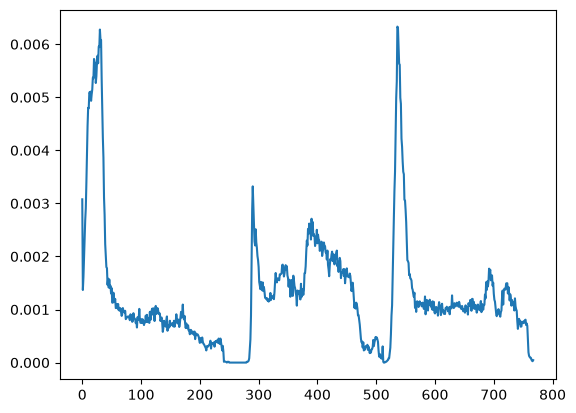

In [4]:

plt.plot(tp1.bgr_histogram(girls))
plt.show()

In [ ]:
print()

1

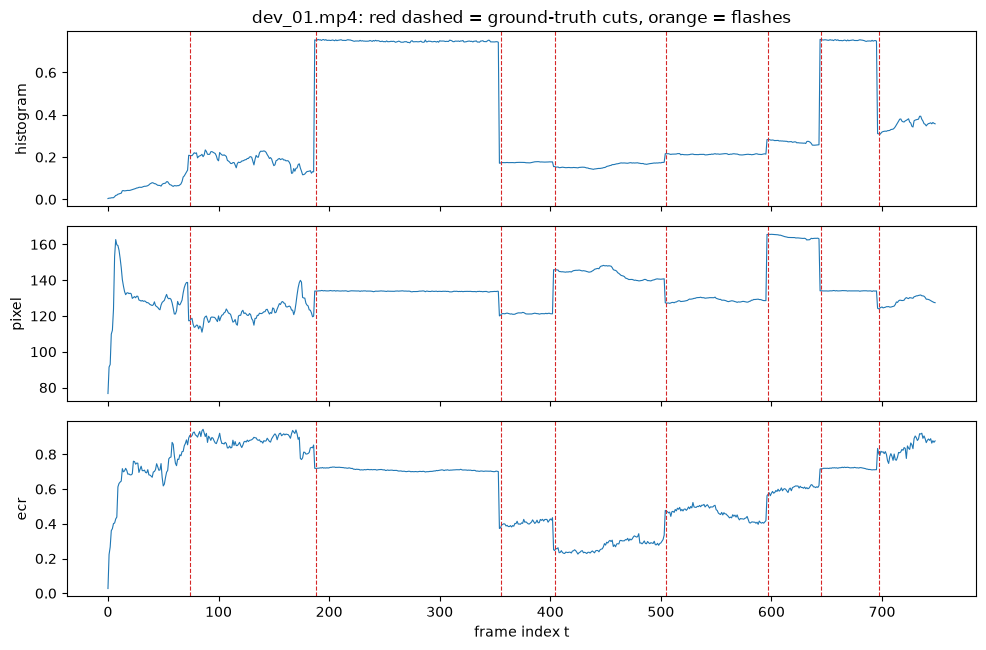

In [ ]:
import json

video = cv.VideoCapture("../input/dev_01.mp4")
with open("../input/dev_01.json", "r") as file:
  data = json.load(file)
fps = data["fps"]

segs = 30
total_frames = fps*segs

d_pixel, d_hist, d_ecr = [], [], []

_, prev_frame = video.read()
for i in range(total_frames-1):
  ret, frame = video.read()

  if not ret:
    break

  hist1 = tp1.bgr_histogram(prev_frame)
  hist2 = tp1.bgr_histogram(frame)

  pixel_dif = tp1.pixel_difference(prev_frame, frame)
  hist_dif = tp1.histogram_distance(hist1, hist2)
  ecr = tp1.edge_change_ration(prev_frame, frame)

  d_pixel.append(pixel_dif)
  d_hist.append(hist_dif)
  d_ecr.append(ecr)

  prev = frame

video.release()

signals = {"histogram": d_hist, "pixel": d_pixel, "ecr":d_ecr}

plotting.plot_signals(signals=signals, gt=data, start=0, end=total_frames-1)

print()



## 3. Part 2 - Gradual transitions and false alarms

## 4. Part 3 - Recurring scenes

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools